# 3. Name tags

Draws a name tag for every participant on top of a template image (`assets/nametag_template.png`) and writes

- `name_tags.pdf`: one tag per page, and
- `name_tag_sheets.pdf`: A3 sheets of 5 x 4 tags, ready to print and cut.

Synthetic data; the template has the conference logo only (no personal information).

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

# Registration export (Google Form -> CSV). The repo ships a synthetic sample;
# point this to your own export to use it for a real event (keep that file out of git).
DATA = Path("sample_registrations.csv")
OUT = Path("output"); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA)
df.columns = df.columns.str.strip()           # the form export has trailing spaces in some headers
df = df[~df["Name"].isna()]                   # drop empty rows
df = df.drop_duplicates(subset="Email address", keep="first")   # people who registered twice
print(len(df), "unique registrations")

import textwrap
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from PIL import Image

template = np.array(Image.open("../assets/nametag_template.png"))
H, W = template.shape[:2]

40 unique registrations


## One name tag

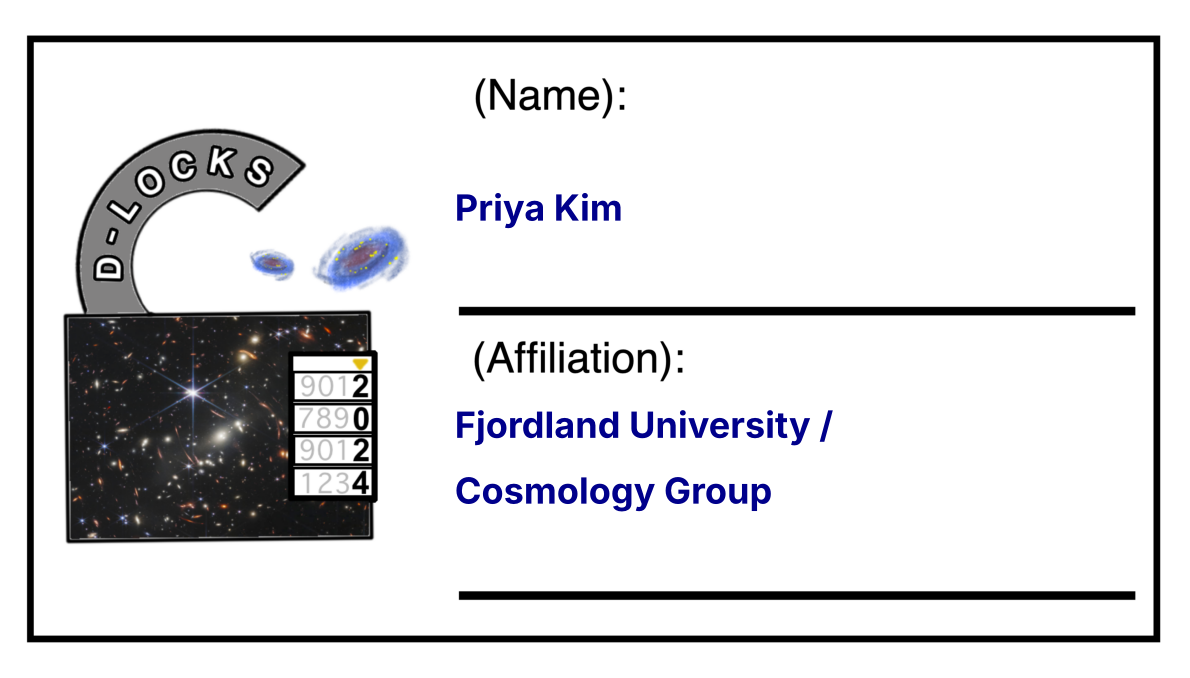

In [ ]:
def draw_tag(ax, name, department, fontsize=26):
    """Draw name and affiliation on the template; long lines are wrapped."""
    ax.imshow(template)
    ax.axis("off")
    for text, y0 in ((name, 0.32), (department, 0.65)):
        y = y0 * H
        for line in textwrap.wrap(str(text), width=24):
            ax.text(0.38 * W, y, line, fontsize=fontsize, weight="bold", color="darkblue")
            y += 0.1 * H

fig, ax = plt.subplots(figsize=(12, 9))
draw_tag(ax, df["Name"].iloc[0], df["Department"].iloc[0])
fig.tight_layout()
fig.savefig("name_tag_example.png", dpi=80)

## All tags (one per page)

In [3]:
with PdfPages(OUT / "name_tags.pdf") as pdf:
    for name, dept in zip(df["Name"], df["Department"]):
        fig, ax = plt.subplots(figsize=(12, 9))
        draw_tag(ax, name, dept)
        fig.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)
print(len(df), "name tags written")

40 name tags written


## A3 sheets, 5 x 4 tags per sheet

In [4]:
PER_SHEET = 20
people = list(zip(df["Name"], df["Department"]))

with PdfPages(OUT / "name_tag_sheets.pdf") as pdf:
    for start in range(0, len(people), PER_SHEET):
        fig, axes = plt.subplots(5, 4, figsize=(4.2 * 3, 2.97 * 3))   # A3 landscape
        for ax, (name, dept) in zip(axes.flat, people[start:start + PER_SHEET]):
            draw_tag(ax, name, dept, fontsize=9)
        for ax in axes.flat[len(people[start:start + PER_SHEET]):]:
            ax.axis("off")                                              # empty slots on the last sheet
        fig.subplots_adjust(wspace=0, hspace=0, left=0, bottom=0, right=1, top=1)
        pdf.savefig(fig, dpi=150)
        plt.close(fig)
print(-(-len(people) // PER_SHEET), "sheets written")

2 sheets written
